# Study Habits Across Fields of Study

Question: do students in different fields study differently, and do they score differently? Habit columns are ordered codes (for example study_hours 0 = less than 1 hour, 4 = more than 5 hours), so we use rank-based tests that do not assume a bell curve.

In [2]:
import os
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/MSDS 621; Project/"
except ImportError:
    DATA_DIR = "./"   # CSV in the same folder as this notebook

FIG_DIR = DATA_DIR + "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150)
    plt.show()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load data and rebuild the field column
One-hot encoded `field` and dropped one category (Arts / Humanities), so a row with all field columns equal to 0 is Arts / Humanities.

In [3]:
cl = pd.read_csv(DATA_DIR + "student_study_habits_cleaned.csv")

field_cols = [c for c in cl.columns if c.startswith("field_")]
names = {"field_commerce_management": "Commerce / Management", "field_computer_science_it": "Computer Science / IT",
         "field_other": "Other", "field_other_engineering": "Other Engineering", "field_science": "Science"}
cl["field"] = cl[field_cols].idxmax(axis=1).map(names)
cl.loc[cl[field_cols].sum(axis=1) == 0, "field"] = "Arts / Humanities"

print("Rows:", len(cl))
print(cl["field"].value_counts().to_string())

habits = ["year", "study_hours", "sleep_hours", "attendance", "revision", "exam_prep", "social_media",
          "distraction", "concentration", "assignment_completion", "confidence", "exam_percentage"]


Rows: 812
field
Commerce / Management    144
Arts / Humanities        140
Other                    139
Science                  133
Other Engineering        132
Computer Science / IT    124


## 2. Mean of each habit by field
The numbers are the actual means. Color only shows each column's ranking across the fields, so it makes small gaps look big (for example, most means sit between 1.8 and 2.2 on a 0-4 scale). Use the tests in section 4 to judge whether a gap is real.

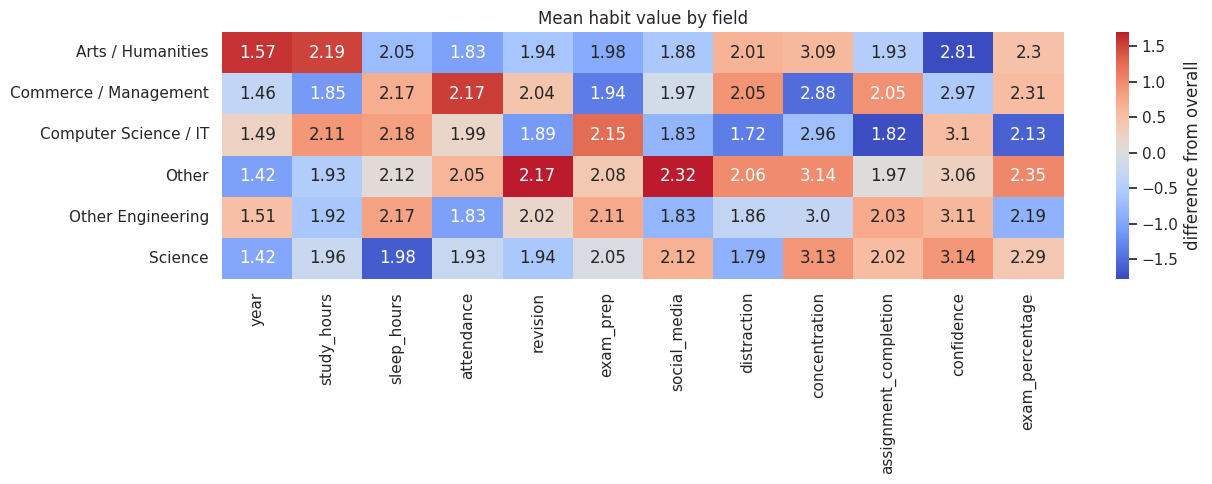

                       year  study_hours  sleep_hours  attendance  revision  exam_prep  social_media  distraction  concentration  assignment_completion  confidence  exam_percentage
field                                                                                                                                                                               
Arts / Humanities      1.57         2.19         2.05        1.83      1.94       1.98          1.88         2.01           3.09                   1.93        2.81             2.30
Commerce / Management  1.46         1.85         2.17        2.17      2.04       1.94          1.97         2.05           2.88                   2.05        2.97             2.31
Computer Science / IT  1.49         2.11         2.18        1.99      1.89       2.15          1.83         1.72           2.96                   1.82        3.10             2.13
Other                  1.42         1.93         2.12        2.05      2.17       2.08         

In [4]:
means = cl.groupby("field")[habits].mean()
z = (means - means.mean()) / means.std()

plt.figure(figsize=(13, 5))
sns.heatmap(z, annot=means.round(2), fmt="", cmap="coolwarm", center=0, cbar_kws={"label": "difference from overall"})
plt.title("Mean habit value by field")
plt.ylabel("")
save("13_field_habit_means")
print(means.round(2).to_string())


## 3. Distributions by field

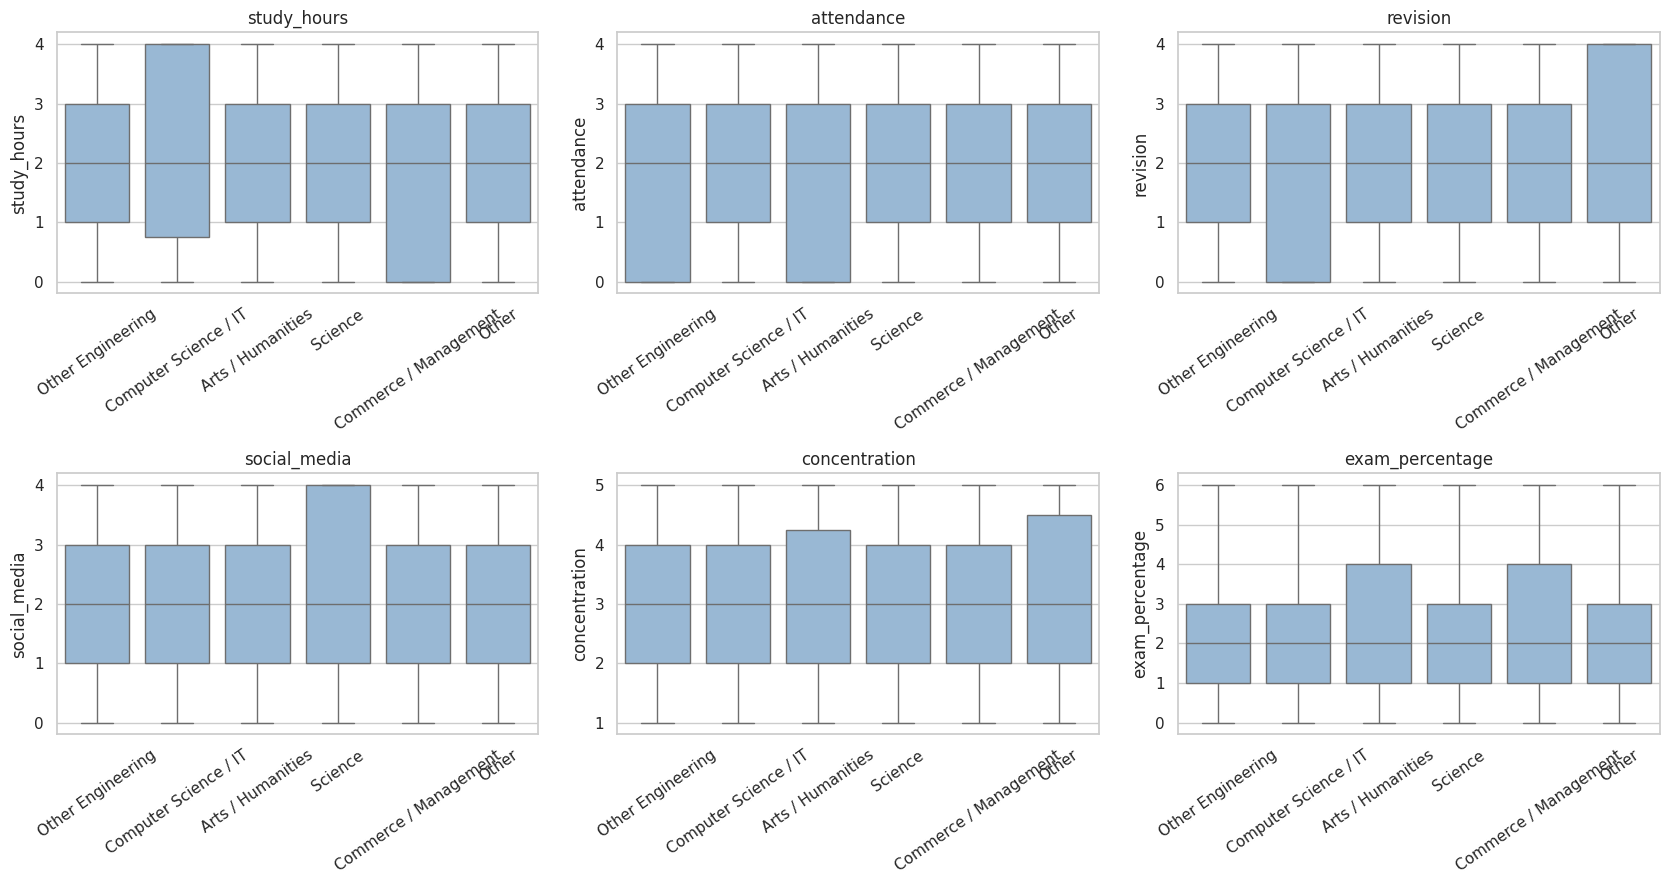

In [5]:
show = ["study_hours", "attendance", "revision", "social_media", "concentration", "exam_percentage"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, h in zip(axes.ravel(), show):
    sns.boxplot(data=cl, x="field", y=h, ax=ax, color="#8FB8DE")
    ax.set_title(h)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
save("14_field_boxplots")


## 4. Do the fields differ? (Kruskal-Wallis test per habit)
- **p (raw)** is the usual p-value.
- **p (Bonferroni)** multiplies by the number of tests (12), because testing many habits makes a small p-value by chance more likely.
- **effect size** (epsilon squared) says how big the difference is. Values under about 0.01 are tiny.

                habit     H  p (raw)  effect size  p (Bonferroni)  significant at 0.05
                 year  2.01   0.8483       0.0000          1.0000                False
          study_hours  5.93   0.3135       0.0011          1.0000                False
          sleep_hours  2.42   0.7881       0.0000          1.0000                False
           attendance  6.31   0.2775       0.0016          1.0000                False
             revision  3.40   0.6385       0.0000          1.0000                False
            exam_prep  2.00   0.8497       0.0000          1.0000                False
         social_media 13.35   0.0203       0.0104          0.2436                False
          distraction  6.97   0.2226       0.0024          1.0000                False
        concentration  3.73   0.5889       0.0000          1.0000                False
assignment_completion  2.23   0.8168       0.0000          1.0000                False
           confidence  5.05   0.4097       

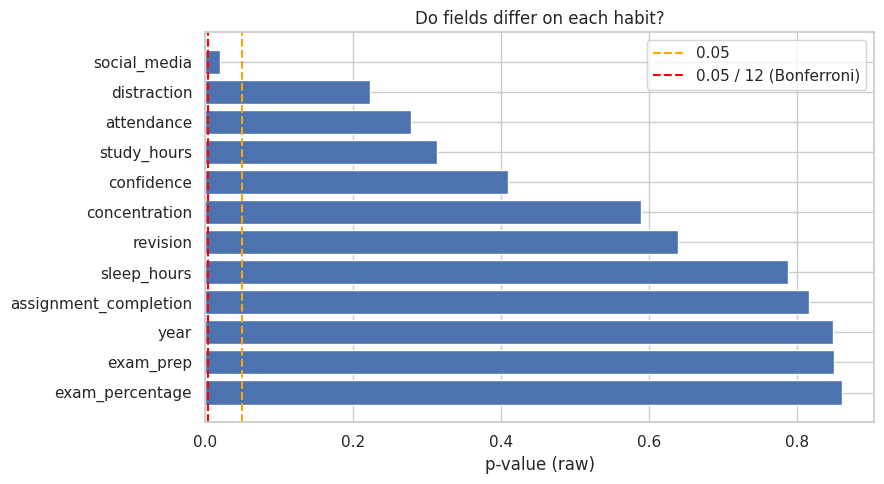

In [6]:
n, k = len(cl), cl["field"].nunique()
rows = []
for h in habits:
    groups = [g[h].values for _, g in cl.groupby("field")]
    H, p = stats.kruskal(*groups)
    rows.append({"habit": h, "H": round(H, 2), "p (raw)": round(p, 4),
                 "effect size": round(max((H - k + 1) / (n - k), 0), 4)})

tests = pd.DataFrame(rows)
tests["p (Bonferroni)"] = (tests["p (raw)"] * len(tests)).clip(upper=1).round(4)
tests["significant at 0.05"] = tests["p (Bonferroni)"] < 0.05
print(tests.to_string(index=False))
tests.to_csv(f"{FIG_DIR}/field_kruskal_tests.csv", index=False)

plt.figure(figsize=(9, 5))
order = tests.sort_values("p (raw)")
plt.barh(order["habit"], order["p (raw)"], color="#4C72B0")
plt.axvline(0.05, color="orange", linestyle="--", label="0.05")
plt.axvline(0.05 / len(tests), color="red", linestyle="--", label="0.05 / 12 (Bonferroni)")
plt.gca().invert_yaxis()
plt.xlabel("p-value (raw)")
plt.title("Do fields differ on each habit?")
plt.legend()
save("15_field_pvalues")


## 5. Follow-up on the smallest p-value
If a habit has a raw p-value under 0.05, compare every pair of fields (Mann-Whitney U, Bonferroni across 15 pairs) to see where the difference comes from.

In [7]:
candidates = tests.loc[tests["p (raw)"] < 0.05, "habit"].tolist()
print("Habits with raw p < 0.05:", candidates)

for h in candidates:
    pairs = []
    for a, b in combinations(sorted(cl["field"].unique()), 2):
        _, p = stats.mannwhitneyu(cl.loc[cl["field"] == a, h], cl.loc[cl["field"] == b, h])
        pairs.append({"field A": a, "field B": b, "p (raw)": round(p, 4), "p (Bonferroni)": round(min(p * 15, 1), 4)})
    pair_df = pd.DataFrame(pairs).sort_values("p (raw)")
    print(f"\nPairwise comparison for {h}")
    print(pair_df.head(5).to_string(index=False))


Habits with raw p < 0.05: ['social_media']

Pairwise comparison for social_media
              field A           field B  p (raw)  p (Bonferroni)
Computer Science / IT             Other   0.0033          0.0502
                Other Other Engineering   0.0035          0.0524
    Arts / Humanities             Other   0.0075          0.1129
Commerce / Management             Other   0.0301          0.4516
Computer Science / IT           Science   0.1052          1.0000


## 6. Do fields differ in what students want to improve?

Chi-square = 30.64, dof = 30, p = 0.4331, Cramer's V = 0.087


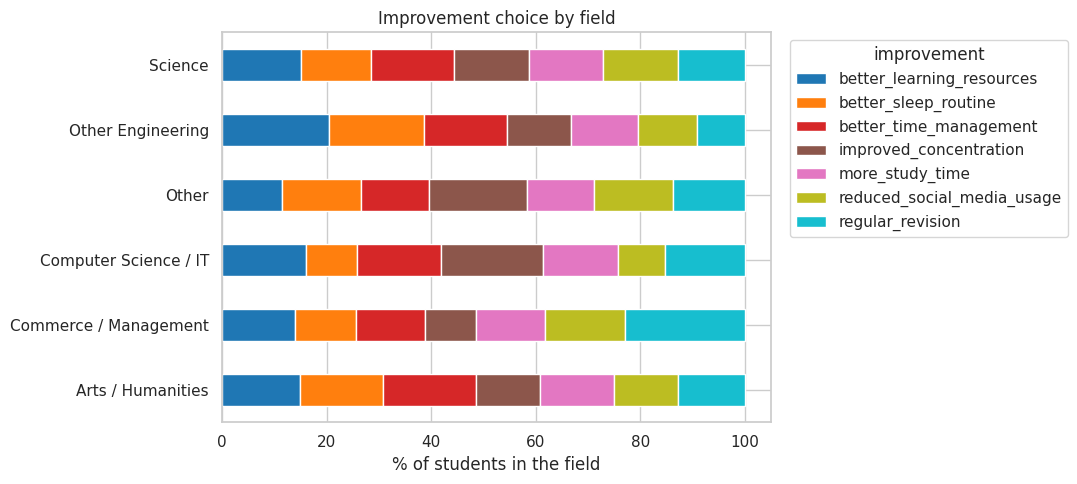

In [8]:
ct = pd.crosstab(cl["field"], cl["improvement"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi-square = {chi2:.2f}, dof = {dof}, p = {p:.4f}, Cramer's V = {cramers_v:.3f}")

(ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind="barh", stacked=True, figsize=(11, 5), colormap="tab10")
plt.xlabel("% of students in the field")
plt.ylabel("")
plt.title("Improvement choice by field")
plt.legend(title="improvement", bbox_to_anchor=(1.02, 1), loc="upper left")
save("16_improvement_by_field")
